# Corpus público y clasificador de texto · LAB04 y LAB05

**INF-8239 Ciencia de Datos II · Unidad 02 (U02.E03)**
Roque Alexis Ventura Vallejo · 100805873

Este notebook integra la auditoría del corpus (LAB04) y la clasificación de texto (LAB05) usando el código reutilizable de `src/inf8239_u02`. Solo lee archivos del proyecto; no modifica `reports/` ni `models/`.

**Requisitos previos:** `uv sync`, `.env` configurado y `uv run python scripts/download_data.py`.
**Ejecución:** abrir con el kernel de `.venv` o ejecutar `uv run jupyter execute --inplace notebooks/01_corpus_clasificador_texto.ipynb`.

## 1. Entorno y configuración

In [1]:
import platform
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split

from inf8239_u02.config import ROOT, settings
from inf8239_u02.data import load_dataset, sha256, validate_dataframe
from inf8239_u02.modeling import build_models

pd.set_option("display.max_colwidth", 110)
LABELS = {0: "Bearish", 1: "Bullish", 2: "Neutral"}
TEXT, TARGET = settings.text_column, settings.target_column

print("Python:", platform.python_version(), "| scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)
print("Fuente:", settings.data_source)
print("URL:", settings.dataset_url)
print("Archivo:", settings.dataset_path.relative_to(ROOT).as_posix())
print("Columnas:", TEXT, "/", TARGET, "| semilla:", settings.random_state)

Python: 3.12.13 | scikit-learn: 1.9.1 | pandas: 2.3.3
Fuente: url
URL: https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment/resolve/main/sent_train.csv
Archivo: data/raw/dataset.csv
Columnas: text / label | semilla: 42


## 2. Selección y procedencia (LAB04 · pasos 4 y 6)

Se compararon dos candidatos de Hugging Face. El hash SHA-256 identifica los bytes descargados: si cambia, cambió la fuente.

In [2]:
display(pd.read_csv(ROOT / "docs/dataset_candidates.csv"))

EXPECTED_SHA = "71aa99d0d37feced03c999ec23b5b25302c92f39d69b6acb0a37aa076c5420e8"
digest = sha256(settings.dataset_path)
print("SHA-256:", digest)
print("Coincide con la versión documentada:", digest == EXPECTED_SHA)

,name,url,license,language,rows,target,decision
0,twitter-financial-news-sentiment,https://huggingface.co/datasets/zeroshot/twitter-financial-news-sentiment,MIT,en,9543,label,aprobado
1,fake_news_corpus_spanish,https://huggingface.co/datasets/mariagrandury/fake_news_corpus_spanish,CC-BY-4.0,es,572,CATEGORY,rechazado


SHA-256: 71aa99d0d37feced03c999ec23b5b25302c92f39d69b6acb0a37aa076c5420e8
Coincide con la versión documentada: True


## 3. Auditoría del corpus (LAB04 · paso 6)

In [3]:
df = load_dataset()
text = df[TEXT].astype(str)
lengths = text.str.len()

print("Filas y columnas:", df.shape)
print("Nulos:", df[[TEXT, TARGET]].isna().sum().to_dict())
print("Duplicados exactos de texto:", int(text.duplicated().sum()))
dist = df[TARGET].map(LABELS).value_counts().to_frame("n")
dist["%"] = (dist["n"] / len(df) * 100).round(1)
display(dist)
display(lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame("caracteres").T)

Filas y columnas: (9543, 2)
Nulos: {'text': 0, 'label': 0}
Duplicados exactos de texto: 0


,n,%
label,,
Neutral,6178,64.7
Bullish,1923,20.2
Bearish,1442,15.1


,count,mean,std,min,50%,90%,99%,max
caracteres,9543.0,85.8,35.1,2.0,79.0,139.0,140.0,190.0


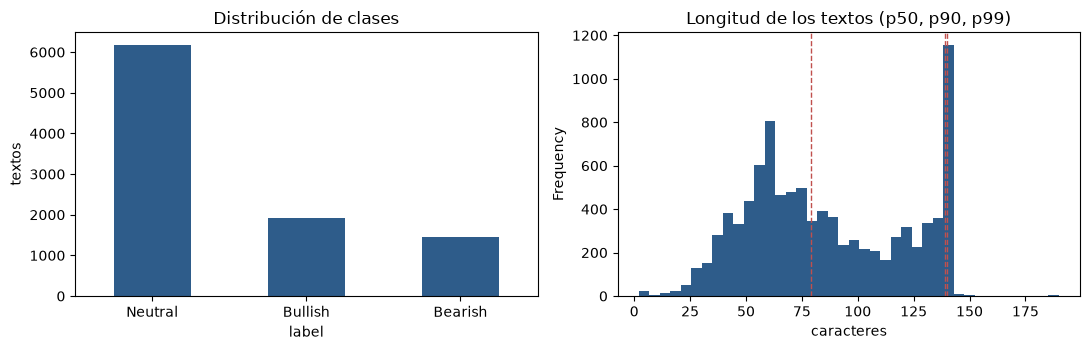

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
dist["n"].plot.bar(ax=axes[0], color="#2E5C8A", rot=0)
axes[0].set_title("Distribución de clases")
axes[0].set_ylabel("textos")
lengths.plot.hist(bins=40, ax=axes[1], color="#2E5C8A")
for p in (0.5, 0.9, 0.99):
    axes[1].axvline(lengths.quantile(p), color="#C0504D", ls="--", lw=1)
axes[1].set_title("Longitud de los textos (p50, p90, p99)")
axes[1].set_xlabel("caracteres")
plt.tight_layout()
plt.show()

**Lectura:** no hay nulos ni duplicados exactos. Neutral concentra cerca del 65 % de los textos, por lo que la accuracy aislada sería engañosa. Los textos son cortos (p99 = 140 caracteres) y no hay textos vacíos.

## 4. Contrato de datos (LAB04 · paso 8)

In [5]:
validate_dataframe(df, TEXT, TARGET)
print("Contrato superado: columnas presentes, sin textos vacíos y con", df[TARGET].nunique(), "clases.")

Contrato superado: columnas presentes, sin textos vacíos y con 3 clases.


## 5. Duplicados y prevención de fuga

Los duplicados pueden inflar el desempeño si aparecen en entrenamiento y prueba. `train_text.py` elimina duplicados de texto antes de la partición, y el vectorizador TF-IDF permanece dentro de cada pipeline para que solo aprenda del entrenamiento.

In [6]:
print("Duplicados de texto antes de la partición:", int(text.duplicated().sum()))
print("Pasos de cada pipeline:", {name: list(p.named_steps) for name, p in build_models(settings.random_state).items()})

Duplicados de texto antes de la partición: 0
Pasos de cada pipeline: {'dummy': ['tfidf', 'model'], 'naive_bayes': ['tfidf', 'model'], 'logistic': ['tfidf', 'model']}


## 6. Entrenamiento de baseline y dos pipelines (LAB05 · paso 3)

Se reproduce exactamente el procedimiento de `scripts/train_text.py`: partición estratificada 75/25 con semilla 42 y los tres pipelines de `build_models`.

In [7]:
data = df.dropna(subset=[TEXT, TARGET]).drop_duplicates(subset=[TEXT])
x_train, x_test, y_train, y_test = train_test_split(
    data[TEXT], data[TARGET], test_size=0.25, random_state=settings.random_state, stratify=data[TARGET]
)
print("Entrenamiento:", len(x_train), "| prueba:", len(x_test))

models = build_models(settings.random_state)
preds, rows = {}, []
for name, model in models.items():
    model.fit(x_train, y_train)
    preds[name] = model.predict(x_test)
    rows.append({
        "modelo": name,
        "f1_macro": f1_score(y_test, preds[name], average="macro"),
        "accuracy": (preds[name] == y_test).mean(),
    })
metrics = pd.DataFrame(rows).sort_values("f1_macro", ascending=False).round(3)
display(metrics)

Entrenamiento: 7157 | prueba: 2386


,modelo,f1_macro,accuracy
2,logistic,0.726,0.795
1,naive_bayes,0.658,0.779
0,dummy,0.262,0.648


In [8]:
saved = pd.read_csv(ROOT / "reports/text_metrics.csv").set_index("model")["f1_macro"].round(3)
check = metrics.set_index("modelo")["f1_macro"]
print("Coincide con reports/text_metrics.csv:", bool((check.reindex(saved.index) == saved).all()))

Coincide con reports/text_metrics.csv: True


## 7. Métricas por clase (LAB05 · paso 4)

In [9]:
names = [LABELS[i] for i in sorted(LABELS)]
for name in ["naive_bayes", "logistic"]:
    print(f"== {name}")
    print(classification_report(y_test, preds[name], target_names=names, digits=3, zero_division=0))

== naive_bayes
              precision    recall  f1-score   support

     Bearish      0.796     0.347     0.484       360
     Bullish      0.754     0.541     0.630       481
     Neutral      0.782     0.954     0.860      1545

    accuracy                          0.779      2386
   macro avg      0.777     0.614     0.658      2386
weighted avg      0.779     0.779     0.757      2386

== logistic
              precision    recall  f1-score   support

     Bearish      0.606     0.611     0.609       360
     Bullish      0.686     0.713     0.699       481
     Neutral      0.875     0.863     0.869      1545

    accuracy                          0.795      2386
   macro avg      0.722     0.729     0.726      2386
weighted avg      0.796     0.795     0.795      2386



**Lectura:**
- **¿Supera el baseline?** Sí: la regresión logística (F1 macro 0.726) supera al Dummy (0.262) y a Naive Bayes (0.658).
- **¿Qué clase se pierde?** Bearish, con el menor recall (0.611).
- **¿Qué predicción es poco confiable?** Bearish, con la menor precision (0.606).
- **¿Existe desbalance?** Sí: support 1 545 Neutral, 481 Bullish y 360 Bearish. El Dummy logra 0.648 de accuracy sin aprender.
- **¿Puede generalizar?** Solo a titulares financieros en inglés de Twitter, mayormente del mercado de EE. UU.

## 8. Matriz de confusión del modelo seleccionado (LAB05 · paso 5)

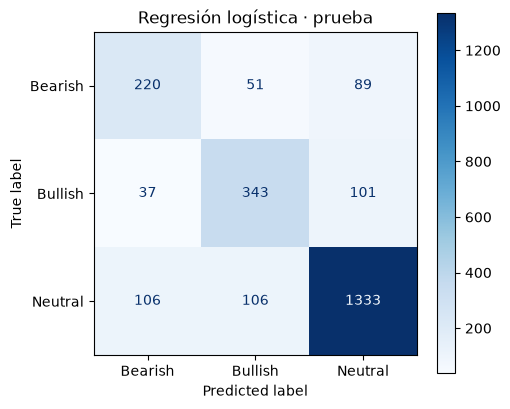

Aciertos por clase (diagonal): {'Bearish': 220, 'Bullish': 343, 'Neutral': 1333}
Confusiones más frecuentes (real, predicho):
Neutral  Bearish    106
         Bullish    106
Bullish  Neutral    101


In [10]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ConfusionMatrixDisplay.from_predictions(y_test, preds["logistic"], display_labels=names, cmap="Blues", ax=ax)
ax.set_title("Regresión logística · prueba")
plt.tight_layout()
plt.show()

cm = pd.DataFrame(confusion_matrix(y_test, preds["logistic"]), index=names, columns=names)
pairs = cm.stack()
off = pairs[[r != c for r, c in pairs.index]].sort_values(ascending=False)
print("Aciertos por clase (diagonal):", {n: int(cm.loc[n, n]) for n in names})
print("Confusiones más frecuentes (real, predicho):")
print(off.head(3).to_string())

**Costo real:** las noticias Neutral marcadas como Bearish o Bullish (106 cada una) son falsas señales de mercado que podrían motivar a comprar o vender sin fundamento. Las 89 noticias Bearish marcadas como Neutral son riesgos negativos que pasan inadvertidos.

## 9. Análisis de errores (LAB05 · paso 6)

In [11]:
errors = pd.read_csv(ROOT / "reports/error_analysis.csv")
print("Errores del modelo seleccionado:", len(errors), "| recalculados ahora:", int((preds["logistic"] != y_test).sum()))
done = errors[errors["category"] != "REVISAR"].copy()
done["real"] = done["real"].map(LABELS)
done["predicted"] = done["predicted"].map(LABELS)
print("Errores categorizados manualmente:", len(done))
display(done[["text", "real", "predicted", "category"]])

Errores del modelo seleccionado: 490 | recalculados ahora: 490
Errores categorizados manualmente: 20


,text,real,predicted,category
0,$BXC (-3.5% pre) Form S-3 BlueLinx Holdings Inc. https://t.co/3hpRHqTF4a,Bearish,Bullish,jerga financiera
1,$SCANX: Mid cap notable movers of interest -- StoneCo (STNE) gains on third quarter results https://t.co/n...,Neutral,Bullish,etiqueta discutible
2,Global Markets: Asian shares mixed as doubts grow on elusive U.S.-China trade deal,Bearish,Bullish,ambigüedad
3,Ahold Delhaize share buyback update,Neutral,Bullish,texto insuficiente
4,$BNKXY - Bankia: Low Valuation Is More Than Justified By Its Fundamental Woes. Continue reading:… https://...,Neutral,Bearish,etiqueta discutible
5,Italy’s Sardines Rally in Backlash Against League’s Salvini,Neutral,Bearish,tema fuera del dominio
6,European stocks get boost from Fed dot plot as ECB decision awaits,Bullish,Neutral,ambigüedad
7,"The Fed may lower the rate on its support facility for money market funds, strategists say https://t.co/Fr...",Neutral,Bearish,jerga financiera
8,Indonesia's Jokowi Warns of Economic Calamity From Forest Fires,Neutral,Bearish,etiqueta discutible
9,$MTLS - Piper hits the Materialise sidelines https://t.co/qlFxZuhkrt,Bearish,Neutral,jerga financiera


,errores
category,
jerga financiera,8
ambigüedad,4
etiqueta discutible,3
tema fuera del dominio,3
texto insuficiente,1
negación,1


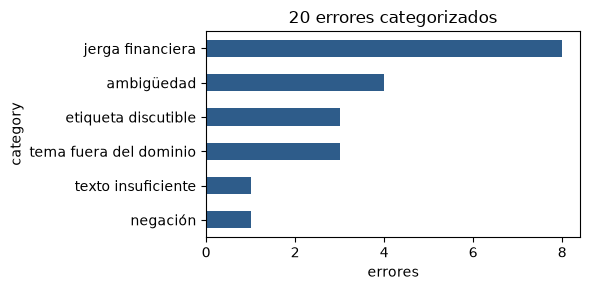

In [12]:
counts = done["category"].value_counts()
display(counts.to_frame("errores"))
counts.sort_values().plot.barh(figsize=(6, 3), color="#2E5C8A", title="20 errores categorizados")
plt.xlabel("errores")
plt.tight_layout()
plt.show()

**Hipótesis verificable:** la categoría dominante es la jerga financiera y las cifras. TF-IDF no capta que "halved", "+14.6%" o "puts" expresan sentimiento, y pierde el signo de porcentajes como "-3.5%". Siguiente experimento: conservar cifras con su signo o incorporar un léxico o modelo del dominio financiero, y comparar el recall de Bearish. Las predicciones no se corrigieron manualmente.

## 10. Modelo guardado e inferencia (LAB05 · pasos 7 y 8)

In [13]:
model = joblib.load(ROOT / "models/text_model.joblib")
print("Mismas predicciones que el modelo reentrenado:", bool((model.predict(x_test) == preds["logistic"]).all()))

samples = {
    "Bullish claro": "Apple stock jumps after record revenue beats analyst estimates",
    "Bearish claro": "Tesla shares plunge after weak earnings and guidance cut",
    "Neutral claro": "Federal Reserve to announce interest rate decision on Wednesday",
    "Ambigua": "Markets mixed as investors await jobs report",
    "Fuera del dominio": "Excelente servicio",
}
pred = model.predict(list(samples.values()))
display(pd.DataFrame({"caso": samples.keys(), "texto": samples.values(), "predicción": [LABELS[p] for p in pred]}))

Mismas predicciones que el modelo reentrenado: True


,caso,texto,predicción
0,Bullish claro,Apple stock jumps after record revenue beats analyst estimates,Bullish
1,Bearish claro,Tesla shares plunge after weak earnings and guidance cut,Bearish
2,Neutral claro,Federal Reserve to announce interest rate decision on Wednesday,Neutral
3,Ambigua,Markets mixed as investors await jobs report,Bearish
4,Fuera del dominio,Excelente servicio,Neutral


**Lectura:** el modelo acierta en titulares financieros claros, pero ante una frase ambigua o fuera del dominio igual devuelve una de las tres clases. La salida es una predicción condicionada por los datos de entrenamiento, no una verdad; por eso la aplicación Streamlit muestra una advertencia de alcance.

## 11. Conclusión

La regresión logística con TF-IDF es el modelo seleccionado (F1 macro 0.726). Su principal debilidad es la clase Bearish, que pierde casi 4 de cada 10 noticias negativas, sobre todo frente a Neutral. El análisis de errores apunta a la jerga financiera como causa dominante. La conclusión completa (400–600 palabras) y el cierre interpretativo están en `docs/cierre_lab05.md`; la lectura detallada de métricas está en `reports/model_evaluation.md`.